In [ ]:
# ========================
# SETUP: Download dataset
# ========================
import urllib.request
import os

csv_url = 'https://raw.githubusercontent.com/pplonski/datasets-for-start/refs/heads/master/telco-customer-churn/Telco-Customer-Churn.csv'

if not os.path.exists('Customer.csv'):
    print('Downloading Customer.csv...')
    import pandas as pd
    import numpy as np
    raw_df = pd.read_csv(csv_url)
    np.random.seed(42)
    loyalty_ids = np.random.randint(100346, 999912, size=len(raw_df))
    loyalty_ids[0]=318537; loyalty_ids[1]=152148; loyalty_ids[2]=326527
    loyalty_ids[3]=845894; loyalty_ids[4]=503388
    df_customer = pd.DataFrame()
    df_customer['LoyaltyID'] = loyalty_ids
    df_customer['Customer ID'] = raw_df['customerID']
    df_customer['Senior Citizen'] = raw_df['SeniorCitizen'].map({0:'No',1:'Yes'})
    df_customer['Partner'] = raw_df['Partner']
    df_customer['Dependents'] = raw_df['Dependents']
    df_customer['Tenure'] = raw_df['tenure']
    df_customer['Phone Service'] = raw_df['PhoneService']
    df_customer['Multiple Lines'] = raw_df['MultipleLines']
    df_customer['Internet Service'] = raw_df['InternetService']
    df_customer['Online Security'] = raw_df['OnlineSecurity']
    df_customer['Online Backup'] = raw_df['OnlineBackup']
    df_customer['Device Protection'] = raw_df['DeviceProtection']
    df_customer['Tech Support'] = raw_df['TechSupport']
    df_customer['Streaming TV'] = raw_df['StreamingTV']
    df_customer['Streaming Movies'] = raw_df['StreamingMovies']
    df_customer['Contract'] = raw_df['Contract']
    df_customer['Paperless Billing'] = raw_df['PaperlessBilling']
    df_customer['Payment Method'] = raw_df['PaymentMethod']
    df_customer['Monthly Charges'] = raw_df['MonthlyCharges']
    df_customer['Total Charges'] = raw_df['TotalCharges']
    df_customer['Churn'] = raw_df['Churn']
    df_customer.to_csv('Customer.csv', index=False)
    print('Customer.csv ready! Shape:', df_customer.shape)
else:
    print('Customer.csv already exists!')


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score,f1_score

import warnings
warnings.filterwarnings('ignore')



In [7]:
df = pd.read_csv('Customer.csv')
df.head()

,LoyaltyID,Customer ID,Senior Citizen,Partner,Dependents,Tenure,Phone Service,Multiple Lines,Internet Service,Online Security,...,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn
0,318537,7590-VHVEG,No,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,152148,5575-GNVDE,No,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,326527,3668-QPYBK,No,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,845894,7795-CFOCW,No,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,503388,9237-HQITU,No,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   LoyaltyID          7043 non-null   int64  
 1   Customer ID        7043 non-null   object 
 2   Senior Citizen     7043 non-null   object 
 3   Partner            7043 non-null   object 
 4   Dependents         7043 non-null   object 
 5   Tenure             7043 non-null   int64  
 6   Phone Service      7043 non-null   object 
 7   Multiple Lines     7043 non-null   object 
 8   Internet Service   7043 non-null   object 
 9   Online Security    7043 non-null   object 
 10  Online Backup      7043 non-null   object 
 11  Device Protection  7043 non-null   object 
 12  Tech Support       7043 non-null   object 
 13  Streaming TV       7043 non-null   object 
 14  Streaming Movies   7043 non-null   object 
 15  Contract           7043 non-null   object 
 16  Paperless Billing  7043 

In [11]:
# to decribe the dataset
df.describe()

,LoyaltyID,Tenure,Monthly Charges
count,7043.000000,7043.000000,7043.000000
mean,550382.651001,32.371149,64.761692
std,260776.118690,24.559481,30.090047
min,100346.000000,0.000000,18.250000
25%,323604.500000,9.000000,35.500000
50%,548704.000000,29.000000,70.350000
75%,776869.000000,55.000000,89.850000
max,999912.000000,72.000000,118.750000


In [13]:
df.isnull().sum()

LoyaltyID            0
Customer ID          0
Senior Citizen       0
Partner              0
Dependents           0
Tenure               0
Phone Service        0
Multiple Lines       0
Internet Service     0
Online Security      0
Online Backup        0
Device Protection    0
Tech Support         0
Streaming TV         0
Streaming Movies     0
Contract             0
Paperless Billing    0
Payment Method       0
Monthly Charges      0
Total Charges        0
Churn                0
dtype: int64

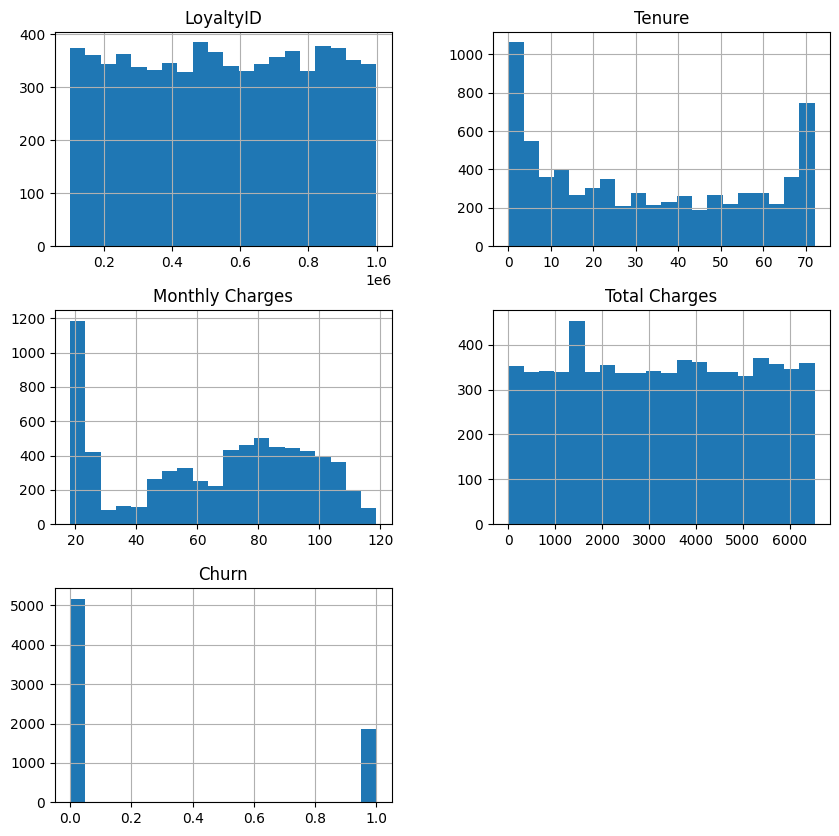

In [20]:
df.hist(bins=20, figsize=(10, 10))
plt.show()

In [25]:

numeric_df = df.select_dtypes(include='number')
print(numeric_df.corr())

                 LoyaltyID    Tenure  Monthly Charges  Total Charges     Churn
LoyaltyID         1.000000 -0.003633        -0.006984      -0.006839  0.009513
Tenure           -0.003633  1.000000         0.247900       0.158523 -0.352229
Monthly Charges  -0.006984  0.247900         1.000000       0.279875  0.193356
Total Charges    -0.006839  0.158523         0.279875       1.000000  0.014479
Churn             0.009513 -0.352229         0.193356       0.014479  1.000000


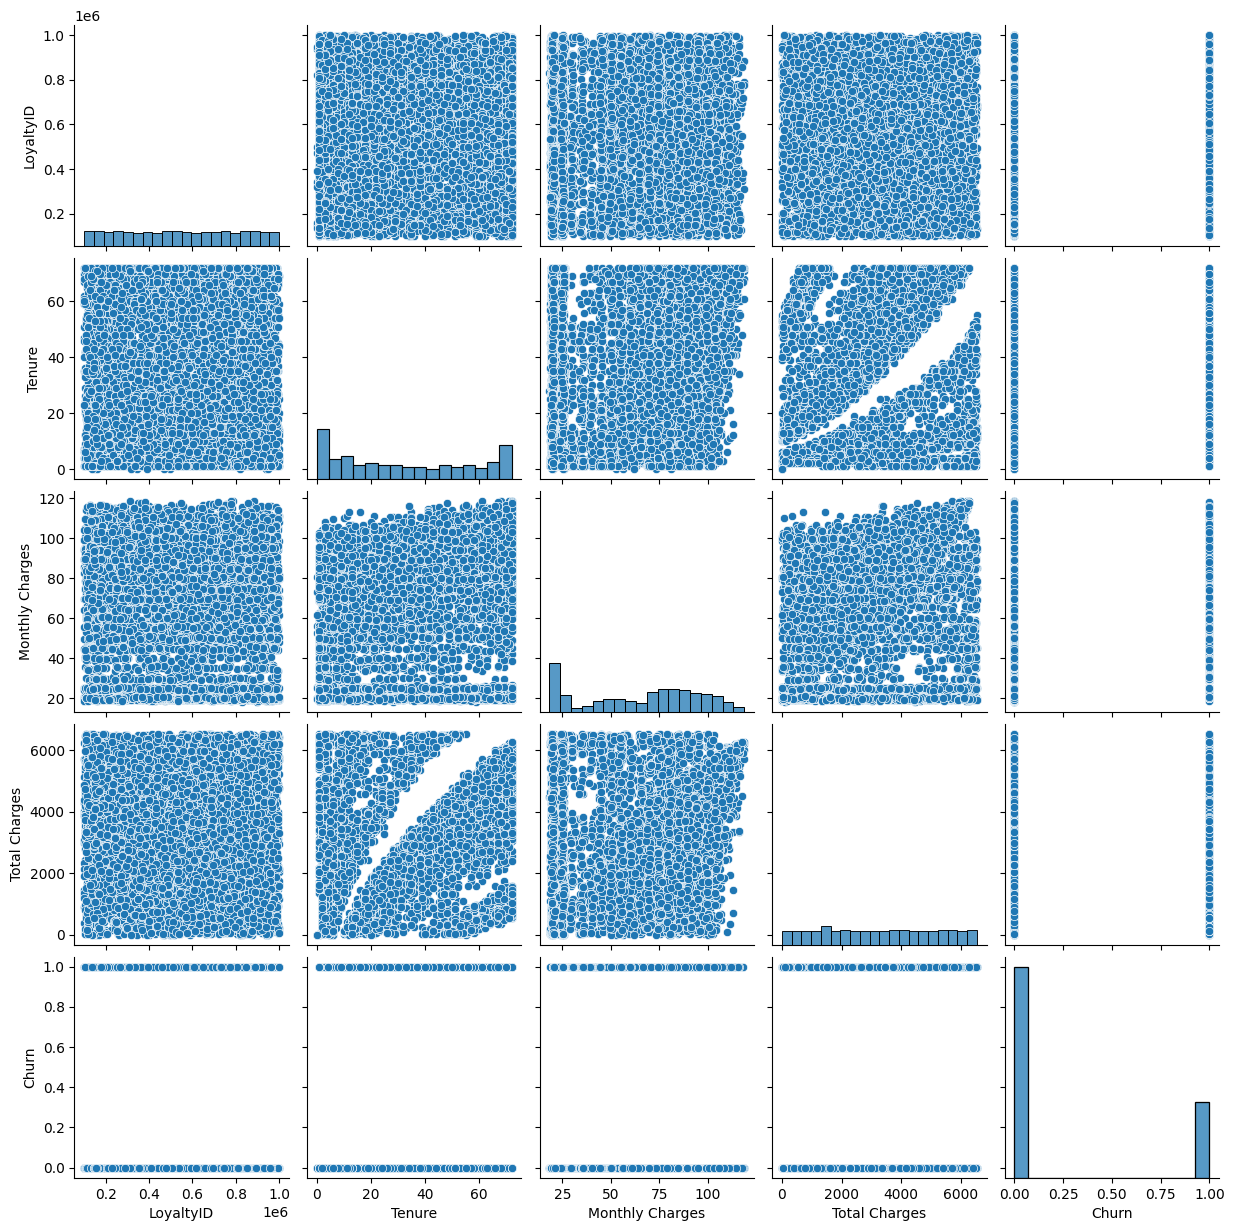

In [31]:
sns.pairplot(df)

In [49]:
# Select only numeric columns before calculating correlation
numeric_df = df.select_dtypes(include='number')
print(numeric_df.corr())

                 LoyaltyID    Tenure  Monthly Charges  Total Charges     Churn
LoyaltyID         1.000000 -0.003633        -0.007030      -0.006839  0.009513
Tenure           -0.003633  1.000000         0.268133       0.158523 -0.352229
Monthly Charges  -0.007030  0.268133         1.000000       0.289637  0.183523
Total Charges    -0.006839  0.158523         0.289637       1.000000  0.014479
Churn             0.009513 -0.352229         0.183523       0.014479  1.000000


In [32]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score,f1_score

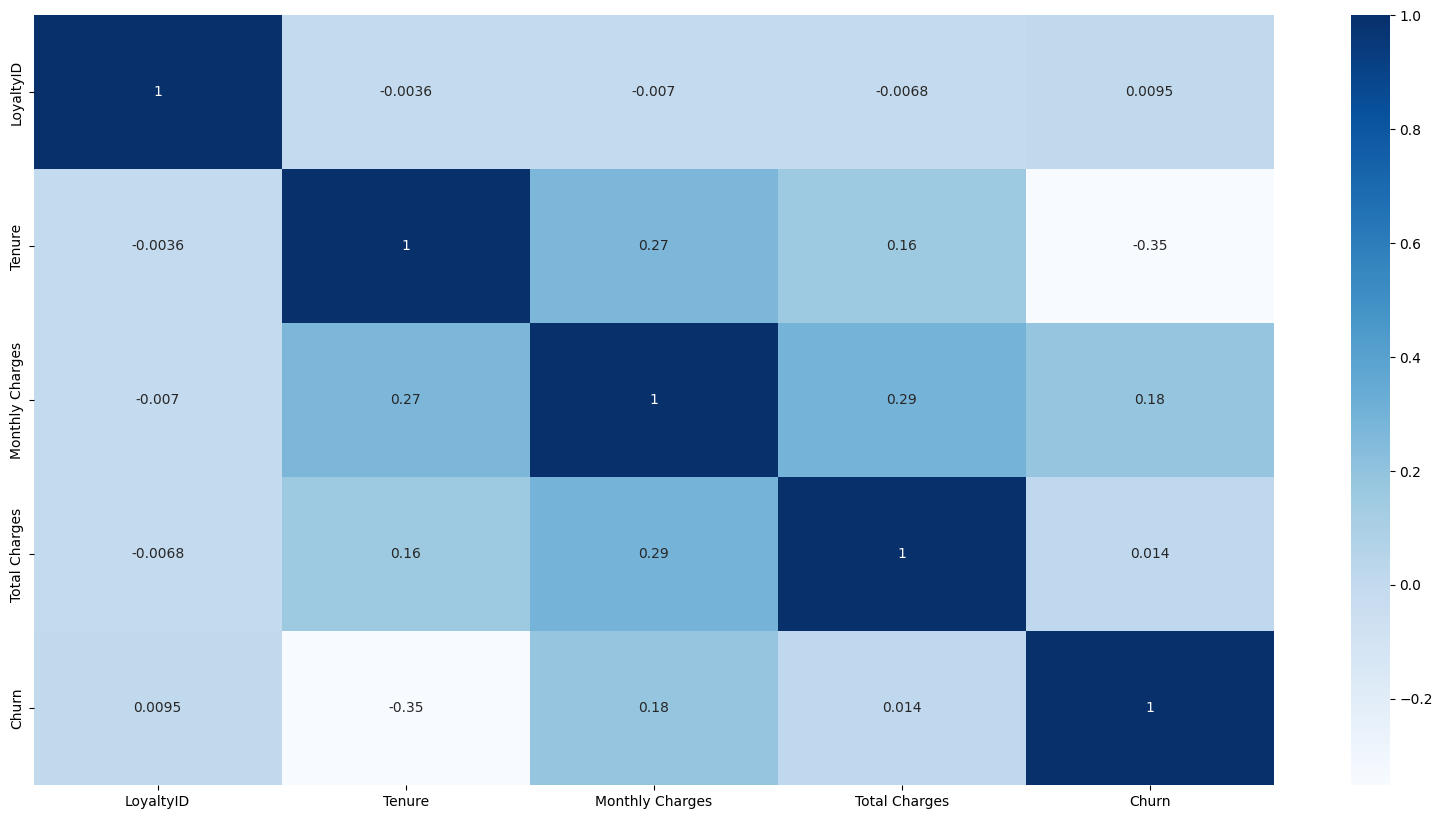

In [56]:
# Select only numeric columns before calculating correlation
numeric_df = df.select_dtypes(include='number')

plt.figure(figsize=(20,10))
sns.heatmap(numeric_df.corr(),cmap='Blues',annot=True)
plt.show()

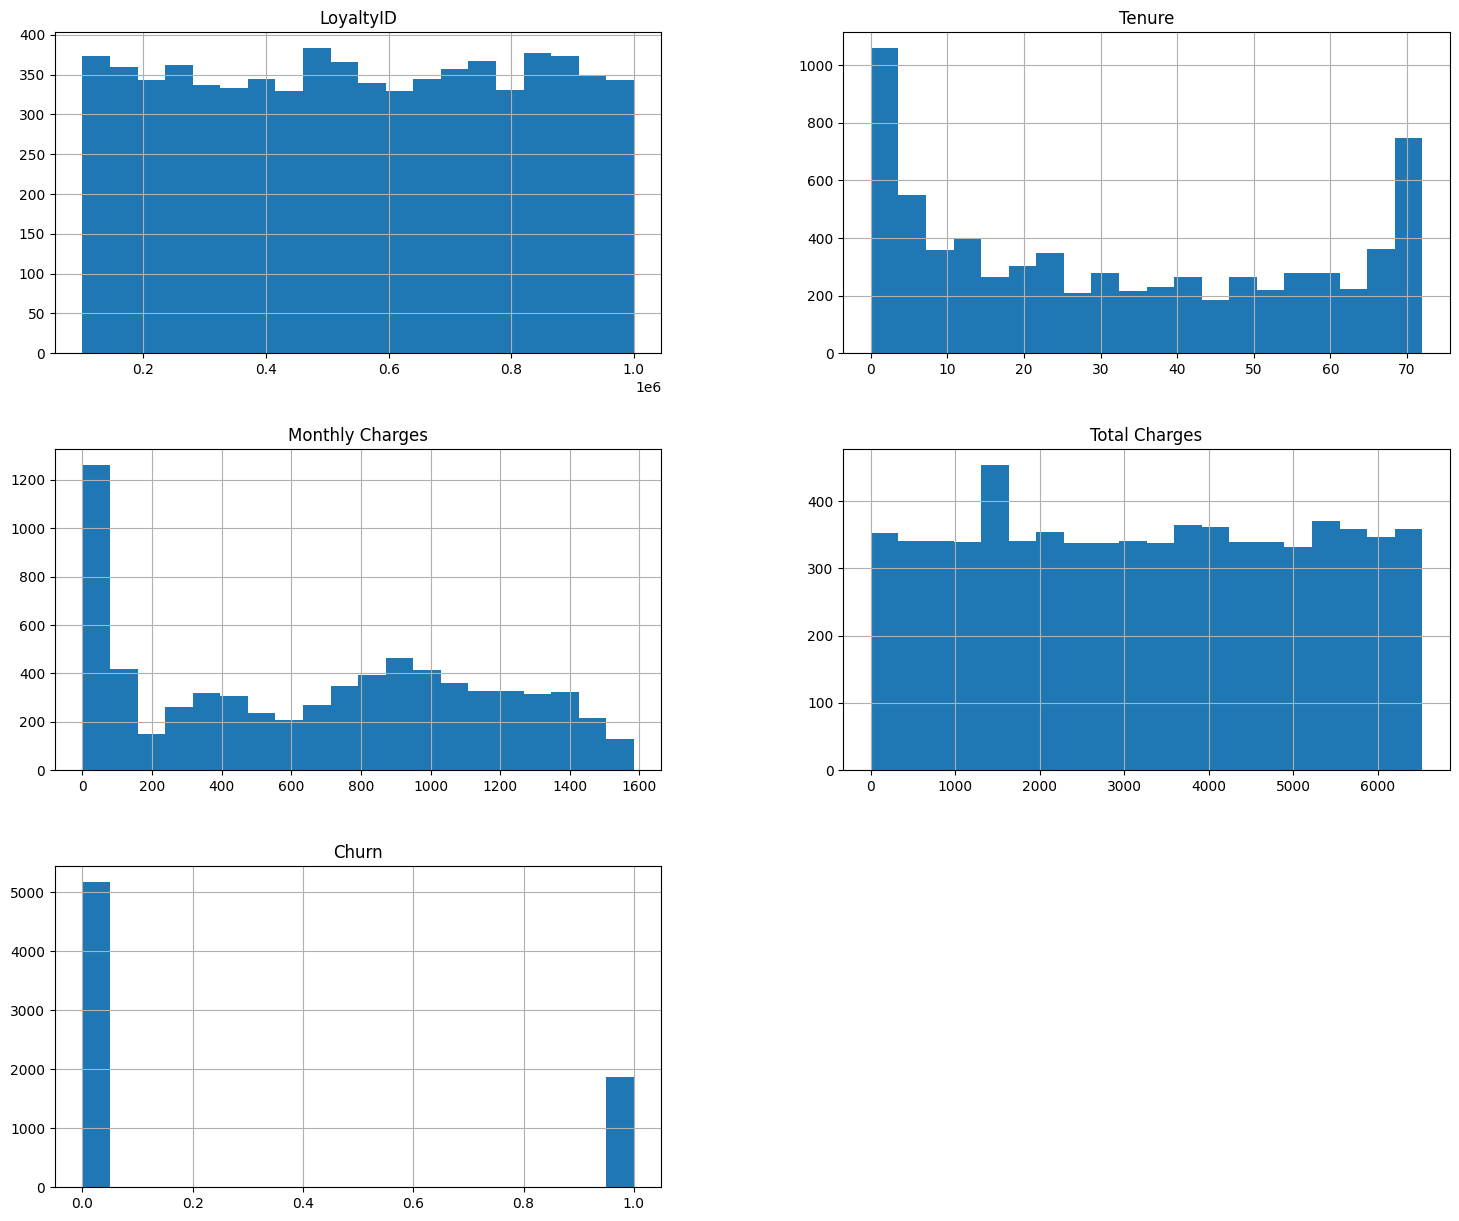

In [60]:
df.hist(bins=20, figsize=(18,15))
plt.show()

In [62]:
#defining x and y values
x = df.drop('Churn',axis=1)
y = df['Churn']


In [63]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=0)

In [ ]:
# =========================================
# STEP 1: Clean 'Total Charges' column
# =========================================
df['Total Charges'] = pd.to_numeric(df['Total Charges'], errors='coerce')
df['Total Charges'] = df['Total Charges'].fillna(0)

# =========================================
# STEP 2: Define Features (X) and Target (y)
# =========================================
x = df.drop(columns=['Churn', 'Customer ID', 'LoyaltyID'])
y = df['Churn'].map({'Yes': 1, 'No': 0})

# =========================================
# STEP 3: Train / Test Split
# =========================================
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0)

# =========================================
# STEP 4: Encode Categorical Columns
# =========================================
non_numeric_cols = x_train.select_dtypes(exclude=['number']).columns
print("Encoding columns:", list(non_numeric_cols))

for col in non_numeric_cols:
    le = LabelEncoder()
    x_train[col] = le.fit_transform(x_train[col].astype(str))
    x_test[col] = le.transform(x_test[col].astype(str))

# =========================================
# STEP 5: Feature Scaling
# =========================================
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

# =========================================
# STEP 6: Train Logistic Regression
# =========================================
model = LogisticRegression(max_iter=1000, random_state=0)
model.fit(x_train_scaled, y_train)
print("Model trained successfully!")

# =========================================
# STEP 7: Evaluate Model
# =========================================
y_pred = model.predict(x_test_scaled)

print("\n" + "="*50)
print(f"  ACCURACY : {accuracy_score(y_test, y_pred)*100:.2f}%")
print(f"  F1 SCORE : {f1_score(y_test, y_pred):.4f}")
print("="*50)
print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))
